# 02 · Aşama 2 — Temel anomali tespit modelleri
| Model | Görevi |
|---|---|
| Isolation Forest | referans anomali tespit modeli |
| Hafif Autoencoder (32-16-**8**-16-32) | temel hafif sinir ağı |
| AE gizil uzay Mahalanobis skoru | alternatif skor (Aşama 4'te B5 karşılaştırması) |

Tüm modeller **yalnızca normal-eğitim** verisiyle eğitilir. Erken durdurma **normal-doğrulama** yeniden oluşturma
kaybına göre yapılır. Bilinen saldırılar (geliştirme-doğrulama) yalnızca tek bir amaçla kullanılır: 2–3 AE boyutunu
karşılaştırmak. Görülmeyecek ailelere dokunulmaz. Skorlar her tohum için önbelleğe alınır; Aşama 3–4 yeniden eğitim yapmaz.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6], '03_kararlar': [], '04b_host_eslesmesi': False}


In [2]:
import tensorflow as tf
from trustids import data as D, models as M, evaluation as E, metrics as MT, conformal as C
P = D.load_prepared(ART / "prepared")
X, T = P["X"], P["types"]
print({k: v.shape for k, v in X.items()})
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

{'benign_train': (8370, 53), 'benign_val': (1674, 53), 'benign_cal': (3348, 53), 'benign_test': (3349, 53), 'dev_val': (23930, 53), 'dev_test': (23928, 53), 'heldout_test': (9547, 53)}
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## AE boyut karşılaştırması (tohum 0) — bilinen saldırıların tek kullanımı
Önceden kaydedilmiş kural: profesörün mimarisi `ae_32_16_8` korunur; başka bir boyut ancak geliştirme-doğrulama PR-AUC değerinde 0,01'den fazla daha iyiyse seçilir.

In [3]:
CKPT = utils.checkpoint_ok(ART, cfg, RESUME)       # aynı ayarlarla üretilmiş ara sonuçlar yeniden kullanılır
if CKPT and (ART / "ae_selection.json").exists():
    SEL = utils.load_json(ART / "ae_selection.json"); CHOSEN = SEL["chosen"]
    print("Kayıtlı AE seçimi kullanılıyor (devam modu):", CHOSEN)
    cmp = pd.DataFrame(SEL["comparison"]).T
else:
  utils.set_seed(cfg.train_seeds[0])
  rows = {}
  for name, spec in cfg.ae_variants.items():
    print(f"{name} eğitiliyor (en fazla {cfg.epochs} epoch; birkaç dakika sürebilir)...", flush=True)
    m = M.build_autoencoder(X["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
    h = M.train_autoencoder(m, X["benign_train"], X["benign_val"], cfg.epochs, cfg.batch_size, cfg.patience,
                           conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
    s_val = np.concatenate([M.ae_score(m, X["benign_val"]), M.ae_score(m, X["dev_val"])])
    y_val = np.r_[np.zeros(len(X["benign_val"])), np.ones(len(X["dev_val"]))]
    rows[name] = {"parametre": M.count_parameters(m), "en_iyi_dogrulama_kaybi": float(min(h["val_loss"])),
                  "epoch": len(h["val_loss"]), "gelistirme_dogrulama_pr_auc": MT.binary_metrics(y_val, s_val, s_val > np.inf)["pr_auc"]}
    print(f"  {name} tamam: {len(h['val_loss'])} epoch, durma nedeni: {h['stopped_by']}", flush=True)
  cmp = pd.DataFrame(rows).T
  best = cmp["gelistirme_dogrulama_pr_auc"].idxmax()
  CHOSEN = best if cmp.loc[best, "gelistirme_dogrulama_pr_auc"] > cmp.loc[cfg.ae_default, "gelistirme_dogrulama_pr_auc"] + 0.01 else cfg.ae_default
  utils.save_json({"comparison": cmp.to_dict(orient="index"), "chosen": CHOSEN}, ART / "ae_selection.json")
print("Seçilen AE:", CHOSEN); cmp

Kayıtlı AE seçimi kullanılıyor (devam modu): ae_32_16_8
Seçilen AE: ae_32_16_8


,parametre,en_iyi_dogrulama_kaybi,epoch,gelistirme_dogrulama_pr_auc
ae_32_16_8,4829.0,0.000746,1274.0,0.986018
ae_16_8_4,2121.0,0.002695,854.0,0.977915
ae_32_16_8_do,4829.0,0.003014,401.0,0.981189


## Her tohum için eğitim ve tüm bölmelerin skorlarının önbelleğe alınması

In [4]:
spec = cfg.ae_variants[CHOSEN]
(ART / "training").mkdir(exist_ok=True)
for seed in cfg.train_seeds:
    if CKPT and E.scores_path(cfg, seed).exists() and (ART / "training" / f"seed{seed}.json").exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    utils.set_seed(seed)
    print("tohum", seed, "eğitiliyor...", flush=True)
    scores = {}
    ifo = M.fit_iforest(X["benign_train"], cfg.iforest_estimators, seed)
    ae = M.build_autoencoder(X["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
    hist = M.train_autoencoder(ae, X["benign_train"], X["benign_val"], cfg.epochs, cfg.batch_size, cfg.patience,
                           conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
    lat = M.LatentMahalanobis(ae).fit(X["benign_train"])
    for split, Xs in X.items():
        scores[("iforest", split)] = M.iforest_score(ifo, Xs)
        scores[("ae", split)] = M.ae_score(ae, Xs)
        scores[("latent", split)] = lat.score(Xs)
    E.save_scores(cfg, seed, scores)
    # final aşama: HER tohumun modeli kaydedilir (Aşama 5–9 on tohumla bu modelleri kullanır)
    (ART / "models").mkdir(exist_ok=True)
    ae.save(str(ART / "models" / f"ae_seed{seed}.keras"))
    utils.save_json(hist, ART / "models" / f"ae_seed{seed}_history.json")
    utils.save_json({"tohum": seed, "ae_parametre": M.count_parameters(ae), "epoch": len(hist["val_loss"]),
                     "durma_nedeni": hist["stopped_by"], "en_iyi_epoch": hist["best_epoch"],
                     "en_iyi_dogrulama_kaybi": float(min(hist["val_loss"]))}, ART / "training" / f"seed{seed}.json")
    print("tohum", seed, "tamam (Drive'a kaydedildi)")
summary = pd.DataFrame([utils.load_json(ART / "training" / f"seed{s}.json") for s in cfg.train_seeds]); utils.save_json(summary.to_dict(orient="records"), ART / "training_summary.json")
print("Durma nedenleri:", summary["durma_nedeni"].value_counts().to_dict(), "| üst sınır:", cfg.epochs, "epoch")
summary

tohum 0 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 1 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 2 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 3 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 4 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 5 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 6 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 7 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 8 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 9 Drive'da kayıtlı, atlanıyor (devam modu)
Durma nedenleri: {'relative_plateau': 9, 'epoch_cap': 1} | üst sınır: 1500 epoch


,tohum,ae_parametre,epoch,durma_nedeni,en_iyi_epoch,en_iyi_dogrulama_kaybi
0,0,4829,1274,relative_plateau,1273,0.000746
1,1,4829,739,relative_plateau,728,0.001332
2,2,4829,987,relative_plateau,978,0.000769
3,3,4829,923,relative_plateau,922,0.000798
4,4,4829,1306,relative_plateau,1301,0.000889
5,5,4829,1500,epoch_cap,1500,0.000789
6,6,4829,733,relative_plateau,724,0.000856
7,7,4829,995,relative_plateau,993,0.000980
8,8,4829,868,relative_plateau,844,0.000675
9,9,4829,1324,relative_plateau,1315,0.000904


## Yeniden oluşturma hatası dağılımları (tohum 0)

ransomware   n=   248  medyan hata=0.004842
xss          n=  8285  medyan hata=0.0221
mitm         n=  1014  medyan hata=0.0009978


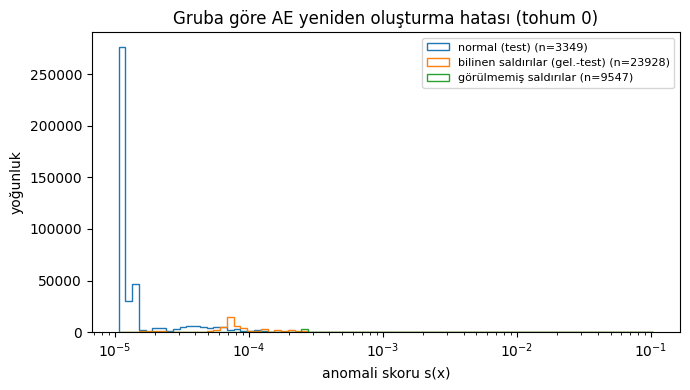

In [5]:
from trustids import plotting as PL
S = E.load_scores(cfg, cfg.train_seeds[0])
groups = {"normal (test)": S[("ae", "benign_test")],
          "bilinen saldırılar (gel.-test)": S[("ae", "dev_test")],
          "görülmemiş saldırılar": S[("ae", "heldout_test")]}
PL.score_distributions(groups, "Gruba göre AE yeniden oluşturma hatası (tohum 0)", FIG / "02_ae_score_distributions.png");
for fam in cfg.heldout_families:
    v = S[("ae", "heldout_test")][T["heldout_test"] == fam]
    print(f"{fam:12s} n={len(v):6d}  medyan hata={np.median(v) if len(v) else float('nan'):.4g}")

## İlk tespit sonuçları: α düzeyinde ikili kural (B2), profesörün metrikleri
Eşik = normal-kalibrasyondan konformal τ_H (α düzeyinde). Bilinen ve görülmemiş saldırılar için ayrı raporlanır.

In [6]:
rows = []
for model in ["ae", "iforest", "latent"]:
    tau = C.thresholds(S[(model, "benign_cal")], cfg.alpha, cfg.beta)["tau_H"]
    for part in ["dev_test", "heldout_test"]:
        s = np.r_[S[(model, "benign_test")], S[(model, part)]]
        y = np.r_[np.zeros(len(S[(model, "benign_test")])), np.ones(len(S[(model, part)]))]
        r = MT.binary_metrics(y, s, s > tau)
        rows.append({"model": model, "saldırılar": "bilinen" if part == "dev_test" else "görülmemiş", **r})
b2 = pd.DataFrame(rows).round(4); b2.to_csv(FIG / "02_binary_B2_seed0.csv", index=False); b2

,model,saldırılar,precision,recall,f1,fpr,pr_auc,roc_auc
0,ae,bilinen,0.9944,0.1843,0.3110,0.0075,0.9742,0.8701
1,ae,görülmemiş,0.9947,0.4892,0.6558,0.0075,0.9871,0.9708
2,iforest,bilinen,0.0000,0.0000,NaN,0.0161,0.9132,0.7753
3,iforest,görülmemiş,0.0000,0.0000,NaN,0.0161,0.8893,0.8722
4,latent,bilinen,0.2459,0.0006,0.0013,0.0137,0.9336,0.7461
5,latent,görülmemiş,0.9546,0.1013,0.1831,0.0137,0.8989,0.7965


## Profesörün Aşama 2 metrikleri: IF ve AE, 10 tohum (ortalama ± standart sapma)

In [7]:
rows = []
for seed in cfg.train_seeds:
    Ss = E.load_scores(cfg, seed)
    for model in ["ae", "iforest", "latent"]:
        tau = C.thresholds(Ss[(model, "benign_cal")], cfg.alpha, cfg.beta)["tau_H"]
        for part in ["dev_test", "heldout_test"]:
            s = np.r_[Ss[(model, "benign_test")], Ss[(model, part)]]
            y = np.r_[np.zeros(len(Ss[(model, "benign_test")])), np.ones(len(Ss[(model, part)]))]
            rows.append({"tohum": seed, "model": model, "saldırılar": "bilinen" if part == "dev_test" else "görülmemiş",
                         **MT.binary_metrics(y, s, s > tau)})
B2ALL = pd.DataFrame(rows); B2ALL.to_csv(FIG / "02_binary_B2_10seeds.csv", index=False)
B2ALL.groupby(["model", "saldırılar"])[["precision", "recall", "f1", "fpr", "pr_auc", "roc_auc"]].agg(["mean", "std"]).round(4)

precision          recall              f1             fpr          pr_auc         roc_auc        
                        mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
model   saldırılar                                                                                                  
ae      bilinen       0.9940  0.0008  0.1691  0.0231  0.2884  0.0331  0.0072  0.0010  0.9730  0.0030  0.8681  0.0169
        görülmemiş    0.9940  0.0028  0.4558  0.0960  0.6188  0.1076  0.0072  0.0010  0.9831  0.0029  0.9654  0.0045
iforest bilinen       0.0000  0.0000  0.0000  0.0000     NaN     NaN  0.0129  0.0014  0.9135  0.0100  0.7786  0.0277
        görülmemiş    0.0000  0.0000  0.0000  0.0000     NaN     NaN  0.0129  0.0014  0.8878  0.0089  0.8705  0.0140
latent  bilinen       0.1232  0.2030  0.0003  0.0007  0.0014  0.0017  0.0101  0.0019  0.9166  0.0256  0.7327  0.0727
        görülmemiş    0.3495  0.4019  0.0189  0.0373  0.0579  0.0819  0.0101  0.0019  0.8412  0.0503  0.7313  0.0873

## Tohum 0 karşılaştırmaları: cihaz öznitelikleri ve sızıntı kontrolü
Aynı AE ve aynı kural; (a) yalnızca cihazda hesaplanabilen akış sayaçları, (b) `ts`/IP/port *dahil* öznitelikler. (b) yalnızca kontroldür: büyük bir sıçrama, kimlik sütunlarının etiketi sızdırdığı anlamına gelir.

In [8]:
rows = []
VAR_DONE = CKPT and (FIG / "02_device_and_leakage_check.csv").exists()
if VAR_DONE:
    print("Kayıtlı tablo kullanılıyor (devam modu)")
for variant in ([] if VAR_DONE else ["prepared_device", "prepared_leakage"]):
    if not (ART / variant / "prepared.npz").exists():
        continue
    Pv = D.load_prepared(ART / variant); Xv = Pv["X"]
    utils.set_seed(cfg.train_seeds[0])
    m = M.build_autoencoder(Xv["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
    M.train_autoencoder(m, Xv["benign_train"], Xv["benign_val"], cfg.epochs, cfg.batch_size, cfg.patience,
                           conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
    tau = C.thresholds(M.ae_score(m, Xv["benign_cal"]), cfg.alpha, cfg.beta)["tau_H"]
    for part in ["dev_test", "heldout_test"]:
        s = np.r_[M.ae_score(m, Xv["benign_test"]), M.ae_score(m, Xv[part])]
        y = np.r_[np.zeros(len(Xv["benign_test"])), np.ones(len(Xv[part]))]
        rows.append({"varyant": variant, "öznitelik": Xv["benign_train"].shape[1],
                     "saldırılar": "bilinen" if part == "dev_test" else "görülmemiş", **MT.binary_metrics(y, s, s > tau)})
VAR = pd.read_csv(FIG / "02_device_and_leakage_check.csv") if VAR_DONE else pd.DataFrame(rows).round(4)
VAR.to_csv(FIG / "02_device_and_leakage_check.csv", index=False); VAR

Kayıtlı tablo kullanılıyor (devam modu)


,varyant,öznitelik,saldırılar,precision,recall,f1,fpr,pr_auc,roc_auc
0,prepared_device,21,bilinen,0.9953,0.3319,0.4978,0.0112,0.9889,0.9406
1,prepared_device,21,görülmemiş,0.9920,0.4970,0.6622,0.0112,0.9860,0.9695
2,prepared_leakage,94,bilinen,0.9972,0.4758,0.6442,0.0082,0.9961,0.9818
3,prepared_leakage,94,görülmemiş,0.9951,0.4905,0.6571,0.0082,0.9891,0.9739


## Öznitelik kümeleri: adil karşılaştırma (10 tohum, aynı satırlar, eşitlenmiş yanlış alarm)
Tek tohumlu karşılaştırmada modeller farklı yanlış alarm oranlarında ve farklı tekrar-temizlenmiş kümelerde çalışıyordu.
Burada üç öznitelik kümesi **ana bölmenin aynı satırları** üzerinde eğitilir, kalibre edilir ve test edilir:

* **tümü** — ana model (önbellekteki skorlar);
* **cihaz** — yalnızca IoT cihazında hesaplanabilen akış sayaçları;
* **sızıntı** — kimlik sütunları (`ts`/IP/port) *dahil* (yalnızca kontrol; ana sonuçlarda kullanılmaz).

Karşılaştırma (a) aynı konformal α düzeyinde ve (b) normal testte **eşitlenmiş %1 yanlış alarm oranında** yapılır.
(b)'deki eşik normal-test üzerinden seçilir; bu bir **analiz yapısıdır** (etiket kullanır), dağıtılabilir bir kural değildir.
Ayrıca cihaz kümesinde, daha az öznitelik nedeniyle bazı test vektörleri bir eğitim vektörüyle aynı olabilir; bu pay
raporlanır ve bu vektörler çıkarılarak da recall hesaplanır.

In [9]:
raw = D.load_raw(cfg.data_path, cfg)
VARIANTS = {"cihaz": D.feature_columns(raw, cfg, feature_set="device"),
            "sızıntı": D.feature_columns(raw, cfg, include_leakage=True)}
XV = {}
for name, cols_v in VARIANTS.items():
    pre_v = D.Preprocessor(max_card=cfg.max_categorical_cardinality if name != "sızıntı" else 100,
                           corr_threshold=cfg.correlation_threshold)
    pre_v.fit(raw.loc[P["index"]["benign_train"]], cols_v)
    XV[name] = {k: pre_v.transform(raw.loc[v]) for k, v in P["index"].items()}
    print(name, "öznitelik:", XV[name]["benign_train"].shape[1])

# cihaz kümesinde eğitim vektörüyle birebir aynı olan test vektörleri
h_train = set(D._row_hashes(XV["cihaz"]["benign_train"]))
SEEN = {k: np.array([h in h_train for h in D._row_hashes(XV["cihaz"][k])]) for k in ["benign_test", "dev_test", "heldout_test"]}
print("cihaz: eğitimde birebir görülmüş test vektörü payı:", {k: round(float(v.mean()), 4) for k, v in SEEN.items()})

def recall_at_fpr(s_benign, s_attack, fpr):
    thr = np.quantile(s_benign, 1 - fpr)
    return float(np.mean(s_attack > thr))

(ART / "featcmp").mkdir(exist_ok=True)
for seed in cfg.train_seeds:
    if CKPT and (ART / "featcmp" / f"seed{seed}.json").exists():
        print("tohum", seed, "Drive'da kayıtlı, atlanıyor (devam modu)"); continue
    rows = []
    sf = E.load_scores(cfg, seed)
    SC = {"tümü": {k: sf[("ae", k)] for k in ["benign_cal", "benign_test", "dev_test", "heldout_test"]}}
    for name in VARIANTS:
        utils.set_seed(seed)
        Xv = XV[name]
        m = M.build_autoencoder(Xv["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
        M.train_autoencoder(m, Xv["benign_train"], Xv["benign_val"], cfg.epochs, cfg.batch_size, cfg.patience,
                           conv_window=cfg.conv_window, conv_rel_tol=cfg.conv_rel_tol)
        SC[name] = {k: M.ae_score(m, Xv[k]) for k in SC["tümü"]}
        if name == "cihaz":   # final aşama: cihaz modeli de kaydedilir (madde 4: FL ve INT8 deneyleri için)
            m.save(str(ART / "models" / f"device_seed{seed}.keras"))
    np.savez_compressed(ART / "scores" / f"device_seed{seed}.npz", **SC["cihaz"])
    for name, sc in SC.items():
        tau = C.thresholds(sc["benign_cal"], cfg.alpha, cfg.beta)["tau_H"]
        for part in ["dev_test", "heldout_test"]:
            row = {"tohum": seed, "öznitelik": name, "saldırılar": "bilinen" if part == "dev_test" else "görülmemiş",
                   "fpr_alpha": float(np.mean(sc["benign_test"] > tau)), "recall_alpha": float(np.mean(sc[part] > tau)),
                   "recall_fpr_1%": recall_at_fpr(sc["benign_test"], sc[part], 0.01)}
            if name == "cihaz":
                nb, na = ~SEEN["benign_test"], ~SEEN[part]
                row["recall_fpr_1%_görülmemiş_vektörler"] = recall_at_fpr(sc["benign_test"][nb], sc[part][na], 0.01)
            rows.append(row)
    utils.save_json(rows, ART / "featcmp" / f"seed{seed}.json")
    print("tohum", seed, "tamam (Drive'a kaydedildi)")
FEATCMP = pd.DataFrame([r for s in cfg.train_seeds for r in utils.load_json(ART / "featcmp" / f"seed{s}.json")]); FEATCMP.to_csv(FIG / "02_feature_sets_10seeds.csv", index=False)
FEATCMP.groupby(["saldırılar", "öznitelik"])[["fpr_alpha", "recall_alpha", "recall_fpr_1%"]].agg(["mean", "std"]).round(4)

cihaz öznitelik: 21
sızıntı öznitelik: 94
cihaz: eğitimde birebir görülmüş test vektörü payı: {'benign_test': 0.0281, 'dev_test': 0.0003, 'heldout_test': 0.0014}
tohum 0 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 1 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 2 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 3 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 4 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 5 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 6 Drive'da kayıtlı, atlanıyor (devam modu)
tohum 7 tamam (Drive'a kaydedildi)
tohum 8 tamam (Drive'a kaydedildi)
tohum 9 tamam (Drive'a kaydedildi)


fpr_alpha         recall_alpha         recall_fpr_1%        
                          mean     std         mean     std          mean     std
saldırılar öznitelik                                                             
bilinen    cihaz        0.0076  0.0015       0.3270  0.0060        0.3328  0.0070
           sızıntı      0.0084  0.0009       0.3716  0.1282        0.4169  0.1308
           tümü         0.0072  0.0010       0.1691  0.0231        0.2247  0.0270
görülmemiş cihaz        0.0076  0.0015       0.5226  0.0674        0.6241  0.0525
           sızıntı      0.0084  0.0009       0.5259  0.0799        0.5553  0.0750
           tümü         0.0072  0.0010       0.4558  0.0960        0.5371  0.0263

In [10]:
from scipy import stats as _st
res = []
for other in ["cihaz", "sızıntı"]:
    for part in ["bilinen", "görülmemiş"]:
        a = FEATCMP[(FEATCMP["saldırılar"] == part) & (FEATCMP["öznitelik"] == other)].sort_values("tohum")["recall_fpr_1%"].to_numpy()
        b = FEATCMP[(FEATCMP["saldırılar"] == part) & (FEATCMP["öznitelik"] == "tümü")].sort_values("tohum")["recall_fpr_1%"].to_numpy()
        p = _st.wilcoxon(a, b).pvalue if not np.allclose(a, b) else 1.0
        res.append({"karşılaştırma": f"{other} - tümü", "saldırılar": part, "ortalama_fark": float(np.mean(a - b)),
                    "kazanan_tohum": int(np.sum(a > b)), "wilcoxon_p": float(p)})
RES = pd.DataFrame(res).sort_values("wilcoxon_p").reset_index(drop=True)
m = len(RES); RES["p_holm"] = np.maximum.accumulate([min(1.0, (m - i) * p) for i, p in enumerate(RES["wilcoxon_p"])])
RES.to_csv(FIG / "02_feature_sets_tests.csv", index=False); RES.round(4)

,karşılaştırma,saldırılar,ortalama_fark,kazanan_tohum,wilcoxon_p,p_holm
0,cihaz - tümü,bilinen,0.1081,10,0.0020,0.0078
1,cihaz - tümü,görülmemiş,0.0869,9,0.0039,0.0117
2,sızıntı - tümü,bilinen,0.1922,9,0.0039,0.0117
3,sızıntı - tümü,görülmemiş,0.0182,5,0.7695,0.7695


## Eğitim süresine duyarlılık (tohum 0): epoch sayısına göre recall
Eğitim süresi sonuçları belirgin biçimde etkileyebildiği için, yakınsama kuralına ek olarak recall'un epoch sayısıyla
nasıl değiştiği raporlanır (yalnızca normal veriyle eğitim; eşikler her noktada konformal α ile yeniden hesaplanır).

,epoch,val_loss,recall_bilinen,recall_görülmemiş,normal_fpr
0,25,0.0049,0.0054,0.1272,0.0063
1,50,0.0029,0.0267,0.1488,0.0066
2,100,0.0019,0.0879,0.1583,0.0075
3,200,0.0013,0.1169,0.4718,0.0075
4,400,0.0010,0.1388,0.4741,0.0069
5,800,0.0009,0.1607,0.4788,0.0078
6,1000,0.0008,0.1607,0.4777,0.0078
7,1500,0.0007,0.1737,0.4842,0.0066


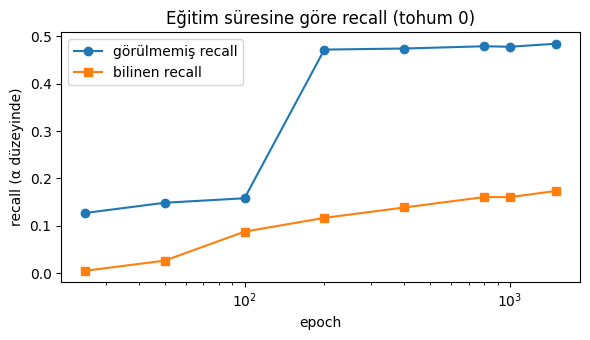

In [11]:
utils.set_seed(cfg.train_seeds[0])
m = M.build_autoencoder(X["benign_train"].shape[1], spec["hidden"], spec["dropout"], cfg.learning_rate)
rows, done = [], 0
EPC_DONE = CKPT and (FIG / "02_recall_vs_epochs_seed0.csv").exists()
for target in ([] if EPC_DONE else [25, 50, 100, 200, 400, 800, 1000, 1500]):
    if QUICK and target > 50:
        break
    m.fit(X["benign_train"], X["benign_train"], epochs=target - done, batch_size=cfg.batch_size, shuffle=True, verbose=0)
    done = target
    tau = C.thresholds(M.ae_score(m, X["benign_cal"]), cfg.alpha, cfg.beta)["tau_H"]
    rows.append({"epoch": target, "val_loss": float(np.mean(M.ae_score(m, X["benign_val"]))),
                 "recall_bilinen": float(np.mean(M.ae_score(m, X["dev_test"]) > tau)),
                 "recall_görülmemiş": float(np.mean(M.ae_score(m, X["heldout_test"]) > tau)),
                 "normal_fpr": float(np.mean(M.ae_score(m, X["benign_test"]) > tau))})
if EPC_DONE:
    print("Kayıtlı epoch eğrisi kullanılıyor (devam modu)"); EPC = pd.read_csv(FIG / "02_recall_vs_epochs_seed0.csv")
else:
    EPC = pd.DataFrame(rows); EPC.to_csv(FIG / "02_recall_vs_epochs_seed0.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(EPC["epoch"], EPC["recall_görülmemiş"], "o-", label="görülmemiş recall")
ax.plot(EPC["epoch"], EPC["recall_bilinen"], "s-", label="bilinen recall")
ax.set_xscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("recall (α düzeyinde)"); ax.legend()
ax.set_title("Eğitim süresine göre recall (tohum 0)"); fig.tight_layout(); fig.savefig(FIG / "02_recall_vs_epochs.png", dpi=150)
EPC.round(4)

In [12]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [], '04b_host_eslesmesi': False}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
